In [5]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("student_performance.csv")

In [6]:
df

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A
...,...,...,...,...,...,...
999995,999996,18.0,95.5,4.8,100.0,A
999996,999997,15.7,82.7,6.7,88.3,A
999997,999998,14.2,85.1,5.8,87.9,A
999998,999999,25.3,90.0,5.3,100.0,A


In [7]:
df1 = pd.DataFrame(df)
print("Dataset:")
print(df1)

Dataset:
        student_id  weekly_self_study_hours  attendance_percentage  \
0                1                     18.5                   95.6   
1                2                     14.0                   80.0   
2                3                     19.5                   86.3   
3                4                     25.7                   70.2   
4                5                     13.4                   81.9   
...            ...                      ...                    ...   
999995      999996                     18.0                   95.5   
999996      999997                     15.7                   82.7   
999997      999998                     14.2                   85.1   
999998      999999                     25.3                   90.0   
999999     1000000                     18.3                   84.6   

        class_participation  total_score grade  
0                       3.8         97.9     A  
1                       2.5         83.9     B  
2  

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
import numpy as np
# Simple Linear Regression
X_simple = df[["weekly_self_study_hours"]]

# Multiple Linear Regression
X_multiple = df[["weekly_self_study_hours","attendance_percentage","class_participation"]]
y = df["total_score"]

# Split the data
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
X_train_m,X_test_m,_,_ = train_test_split(X_multiple,y,test_size = 0.2, random_state = 42)

# Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train_s,y_train)
simple_predictions = simple_model.predict(X_test_s)

print("\n----Simple Linear Regression---")
print("Intercept:",simple_model.intercept_)
print("Coefficient:",simple_model.coef_[0])
print("R2 Score:",r2_score(y_test,simple_predictions))
print("RMSE:",np.sqrt(mean_squared_error(y_test,simple_predictions)))

# Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_m,y_train)
multiple_predictions = multiple_model.predict(X_test_m)

print("\n-----Multiple Linear Regression------")
print("Intercept:",multiple_model.intercept_)
print("Coefficients:",multiple_model.coef_)
print("R2 Score:",r2_score(y_test,multiple_predictions))
print("RMSE:",np.sqrt(mean_squared_error(y_test,multiple_predictions)))


----Simple Linear Regression---
Intercept: 56.97112317922101
Coefficient: 1.8168181254664215
R2 Score: 0.6600435613904075
RMSE: 8.996387974791649

-----Multiple Linear Regression------
Intercept: 56.9535574447703
Coefficients: [ 1.81682003e+00  4.01750743e-04 -2.75562094e-03]
R2 Score: 0.6600425865640975
RMSE: 8.996400873369835


In [18]:
# Predict total_score for a new student
new_student_simple = pd.DataFrame({"weekly_self_study_hours":[6]})
new_student_multiple = pd.DataFrame({
    "weekly_self_study_hours":[6],
    "attendance_percentage":[80],
    "class_participation":[5]
})
print("\nPredicted total score using Simple Regression:",simple_model.predict(new_student_simple)[0])
print("Predicted total score using Multiple Regression:",multiple_model.predict(new_student_multiple)[0])


Predicted total score using Simple Regression: 67.87203193201954
Predicted total score using Multiple Regression: 67.87283956488598


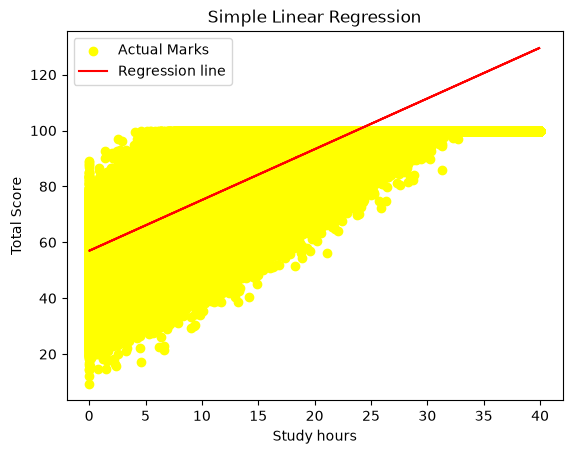

In [22]:
plt.scatter(df["weekly_self_study_hours"],df["total_score"],
            color = "yellow",label = "Actual Marks")
plt.plot(df["weekly_self_study_hours"],
         simple_model.predict(X_simple),
         color = "red",label = "Regression line")
plt.xlabel("Study hours")
plt.ylabel("Total Score")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()